<a href="https://colab.research.google.com/github/guruhbagus73/TUGAS-PREPROCESSING/blob/main/TUGAS_PREPRCESSING_Guruh_Bagus_Prakoso_2404010029.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Individu: Preprocessing Data
## Pembersihan dan Persiapan Data Anggur (Wine) untuk Klasifikasi Kultivar

| | |
|---|---|
| **Nama** | Guruh Bagus Prakoso |
| **NIM** | 2404010029 |
| **Mata Kuliah** | Data Mining |

Notebook ini adalah **kelanjutan dari Tugas Klasifikasi** (identifikasi kultivar anggur). Pada tugas klasifikasi, data sudah dalam keadaan bersih; di sini ditunjukkan tahap yang biasanya dikerjakan lebih dulu, yaitu mengubah **data mentah yang kotor** menjadi data yang siap dipakai model.

> **Cara menjalankan:** letakkan file `data_anggur_mentah_kotor.csv` di folder yang sama dengan notebook ini (di Google Colab: unggah lewat panel *Files*), lalu jalankan semua sel dari atas.

---

## 1. Sumber Data dan Catatan Penting

**Dataset asli:** Wine dari UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/109/wine), berisi 178 sampel anggur dari 3 kultivar dengan 13 hasil analisis kimia.

**Catatan jujur tentang "data kotor":** halaman resmi UCI menyatakan dataset ini **tidak memiliki missing value** ("Has Missing Values? No"), artinya data aslinya memang bersih dan tidak ada versi kotor aslinya. Karena itu, `data_anggur_mentah_kotor.csv` adalah **data kotor simulasi**: dibuat dari data asli dengan menyisipkan masalah yang lazim ditemui pada data lapangan, memakai skrip `buat_data_kotor.py` (seed tetap, hasilnya dapat diulang).

Keuntungannya, karena data asli diketahui sebagai "kunci jawaban", kualitas pembersihan dapat **diukur secara objektif** (Bagian 6), sesuatu yang tidak mungkin dilakukan pada data kotor yang sebenarnya.

| Jenis masalah yang disisipkan | Contoh | Cara penanganan |
|---|---|---|
| Missing value dengan penulisan beragam | `""`, `NA`, `N/A`, `?`, `-`, `null` | Diseragamkan menjadi NaN, lalu diimputasi (KNN) |
| Desimal memakai koma | `3,06` | Diganti menjadi titik, dikonversi ke angka |
| Angka bercampur satuan | `13.2%`, `1065 mg/L` | Simbol dan satuan dibuang |
| Penulisan label tidak konsisten | `K3`, `kultivar 2`, `KULTIVAR 3 `, `1` | Diseragamkan menjadi `Kultivar 1/2/3` |
| Label kosong | `NA`, `?`, kosong | Baris dibuang (target tidak boleh ditebak) |
| Nilai tidak masuk akal | negatif, nol, salah skala (x10 / x100) | Ditandai dengan aturan, dijadikan NaN, lalu diimputasi |
| Baris duplikat | 9 baris salinan persis | Dihapus berdasarkan `id_sampel` |
| Nama kolom berantakan, kolom tidak berguna | `HUE`, `Proline `, `Keterangan` | Dirapikan / dibuang |
| Urutan baris diacak | - | Tidak berpengaruh pada hasil |

## 2. Alur Preprocessing

1. Memuat data mentah sebagai teks dan **mengaudit** masalahnya
2. Merapikan nama kolom
3. Menyeragamkan token kosong menjadi NaN
4. Mengonversi teks menjadi angka (koma, satuan)
5. Menyeragamkan label dan membuang baris tanpa label
6. Menghapus duplikat dan kolom tidak berguna
7. Menandai nilai tidak masuk akal
8. Memeriksa missing value akhir
9. Encoding label
10. Membagi data latih dan data uji (stratified)
11. Imputasi missing value (KNN), parameter hanya dari data latih
12. Normalisasi (StandardScaler), parameter hanya dari data latih
13. Menyimpan hasil
14. **Validasi** hasil terhadap data asli

Urutan penting: perbaikan format dilakukan **sebelum** mencari duplikat (agar `3,06` dan `3.06` dikenali sama), dan pembagian data dilakukan **sebelum** imputasi dan scaling (agar informasi dari data uji tidak bocor ke proses latih).

---
### 3.1 Import Library

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Library berhasil di-import")

Library berhasil di-import


### 3.2 Memuat Data Mentah

In [ ]:
# Semua kolom dibaca sebagai TEKS agar penulisan asli (koma, satuan, "NA", "?") tidak diubah diam-diam oleh pandas
raw = pd.read_csv("data_anggur_mentah_kotor.csv", dtype=str, keep_default_na=False)

print("Jumlah baris dan kolom :", raw.shape)
print()
print(raw.head(10).to_string())

Jumlah baris dan kolom : (187, 16)

  ID Sampel Alcohol Malic Acid   Ash Alcalinity of Ash Magnesium Total Phenols Flavanoids Nonflavanoid  Phenols Proanthocyanins Color Intensity   HUE OD280/OD315 Proline      Kultivar Keterangan
0      S175    13.4       3.91   N/A                23       102           1.8       0.75                  0.43            1.41             7.3   0.7        1.56      750   Kultivar 3           
1      S079   12.33       0.99  1.95              14.8       136           1.9       1.85                  0.35             N/A             3.4  1.06        2.31      750           K2           
2      S056   13.56       1.73  2.46              20.5       116          2.96       2.78                   0.2            2.45            6.25  0.98        3.03     1120   Kultivar 1           
3      S138   12.53       5.51  2.64                25        96          1.79        0.6                  0.63             1.1             N/A  0.82        1.69      515           K3 

Bahkan dari 10 baris pertama sudah terlihat banyak masalah: nilai `N/A`, `NA`, dan `-`; label ditulis `K3`, `K2`, `kultivar 2`, `KULTIVAR 3`; serta nilai yang tidak masuk akal seperti *hue* = 128 dan *color intensity* = 73 pada sampel S016 (nilai wajarnya sekitar 1,28 dan 7,3).

### 3.3 Audit Awal (Mengenali Masalah)

In [ ]:
print("=== Nama kolom (perhatikan spasi dan huruf besar/kecil) ===")
print([c for c in raw.columns])

print()
print("=== Baris duplikat persis :", int(raw.duplicated().sum()), "===")

print()
print("=== Nilai unik pada kolom label (Kultivar) ===")
print(raw["Kultivar"].value_counts().to_string())

# Token yang BUKAN angka murni pada kolom fitur
fitur_raw = [c for c in raw.columns if c not in ("ID Sampel", "Kultivar", "Keterangan")]
def bukan_angka(s):
    try:
        float(s)
        return False
    except ValueError:
        return True

ditemukan = {}
for c in fitur_raw:
    for v in raw.loc[raw[c].map(bukan_angka), c]:
        ditemukan[v] = ditemukan.get(v, 0) + 1
print()
print("=== Isi sel fitur yang bukan angka murni (token : jumlah) ===")
for v, j in sorted(ditemukan.items(), key=lambda x: -x[1])[:15]:
    print(f"  {v!r:14} : {j}")

print()
print("=== Kolom 'Keterangan' terisi pada", int((raw['Keterangan'] != '').sum()), "dari", len(raw), "baris ===")

=== Nama kolom (perhatikan spasi dan huruf besar/kecil) ===
['ID Sampel', 'Alcohol', 'Malic Acid', 'Ash', 'Alcalinity of Ash', 'Magnesium', 'Total Phenols', 'Flavanoids', 'Nonflavanoid  Phenols', 'Proanthocyanins', 'Color Intensity', 'HUE', 'OD280/OD315', 'Proline ', 'Kultivar', 'Keterangan']

=== Baris duplikat persis : 9 ===

=== Nilai unik pada kolom label (Kultivar) ===
Kultivar
Kultivar 2     45
Kultivar 1     38
Kultivar 3     33
kultivar 2      9
K2              8
Cultivar 3      6
Cultivar 1      6
1               6
KULTIVAR 1      5
2               5
K3              4
kultivar 1      4
K1              4
3               3
KULTIVAR 2      3
kultivar 3      2
null            2
KULTIVAR 3      1
NA              1
Cultivar 2      1
?               1

=== Isi sel fitur yang bukan angka murni (token : jumlah) ===
  '?'            : 19
  ''             : 19
  'NA'           : 18
  'N/A'          : 15
  '-'            : 13
  'null'         : 10
  '0,33'         : 2
  '14,34'        : 1

Hasil audit:
- Nama kolom berantakan: `HUE` huruf besar semua, `Proline ` dengan spasi di belakang, `Nonflavanoid  Phenols` dengan dua spasi.
- 9 baris duplikat persis.
- Label kelas ditulis dalam 18 variasi untuk hanya 3 kelas yang sebenarnya, ditambah 3 token kosong (`null`, `NA`, `?`).
- Sel fitur berisi token kosong yang beragam serta angka bermasalah (desimal koma dan satuan).
- Kolom `Keterangan` hampir seluruhnya kosong (hanya 7 dari 187 baris).

### 3.4 Langkah 1: Merapikan Nama Kolom

In [ ]:
# Langkah 1: rapikan nama kolom (huruf kecil, tanpa spasi berlebih, snake_case)
def rapikan(nama):
    nama = nama.strip().lower()
    nama = re.sub(r"[^a-z0-9]+", "_", nama).strip("_")
    return nama

df = raw.rename(columns={c: rapikan(c) for c in raw.columns})
fitur = [c for c in df.columns if c not in ("id_sampel", "kultivar", "keterangan")]
print("Nama kolom setelah dirapikan:")
print(list(df.columns))

Nama kolom setelah dirapikan:
['id_sampel', 'alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280_od315', 'proline', 'kultivar', 'keterangan']


### 3.5 Langkah 2: Menyeragamkan Missing Value

Jumlah sel kosong per kolom (setelah semua token diseragamkan):
alcohol                  5
malic_acid               9
ash                     10
alcalinity_of_ash        9
magnesium                5
total_phenols           11
flavanoids               6
nonflavanoid_phenols     5
proanthocyanins         10
color_intensity          9
hue                      8
od280_od315              4
proline                  3
kultivar                 4

Total sel kosong pada fitur : 94 (3.87% dari seluruh sel fitur)


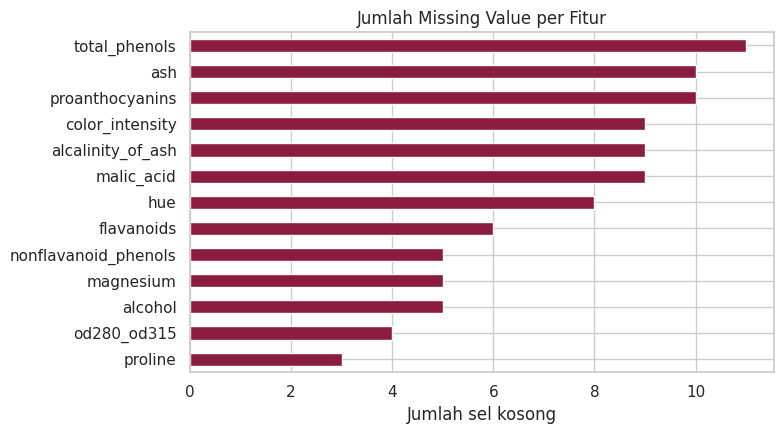

In [ ]:
# Langkah 2: samakan semua penulisan "kosong" menjadi NaN
TOKEN_KOSONG = {"", "na", "n/a", "?", "-", "null", "nan", "none"}

def ke_nan(s):
    return np.nan if s.strip().lower() in TOKEN_KOSONG else s

for c in fitur + ["kultivar"]:
    df[c] = df[c].map(ke_nan)

print("Jumlah sel kosong per kolom (setelah semua token diseragamkan):")
print(df[fitur + ["kultivar"]].isnull().sum().to_string())
print()
print("Total sel kosong pada fitur :", int(df[fitur].isnull().sum().sum()),
      f"({df[fitur].isnull().sum().sum() / df[fitur].size * 100:.2f}% dari seluruh sel fitur)")

plt.figure(figsize=(8, 4.5))
df[fitur].isnull().sum().sort_values().plot(kind="barh", color="#8c1c3d")
plt.title("Jumlah Missing Value per Fitur")
plt.xlabel("Jumlah sel kosong")
plt.tight_layout()
plt.show()

Setelah semua token diseragamkan, terdapat 94 sel fitur kosong (sekitar 3,87%) dan 4 label kosong. Missing value tersebar di semua fitur, tanpa ada fitur yang hampir kosong, sehingga tidak ada fitur yang perlu dibuang.

### 3.6 Langkah 3: Konversi Teks menjadi Angka

In [ ]:
# Langkah 3: ubah teks menjadi angka (desimal koma -> titik, buang satuan seperti %, mg/L)
koma, satuan = 0, 0

def ke_angka(s):
    global koma, satuan
    if pd.isna(s):
        return np.nan
    t = s.strip()
    if "," in t and re.fullmatch(r"-?\d+,\d+", t):
        koma += 1
        t = t.replace(",", ".")
    bersih = re.sub(r"[^0-9.\-]", "", t)          # buang huruf, %, spasi, dll.
    if bersih != t:
        satuan += 1
    return float(bersih) if bersih not in ("", "-", ".") else np.nan

for c in fitur:
    df[c] = df[c].map(ke_angka).astype(float)

print("Sel dengan desimal koma yang diperbaiki :", koma)
print("Sel dengan satuan/simbol yang dibuang   :", satuan)
print()
print("Tipe data setelah konversi:")
print(df[fitur].dtypes.value_counts().to_string())
print()
print(df[fitur].describe().round(2).T[["count", "min", "max"]].to_string())

Sel dengan desimal koma yang diperbaiki : 11
Sel dengan satuan/simbol yang dibuang   : 8

Tipe data setelah konversi:
float64    13

                      count     min      max
alcohol               182.0   11.03    14.83
malic_acid            178.0    0.89    18.10
ash                   177.0    1.36     3.23
alcalinity_of_ash     178.0   10.60    30.00
magnesium             182.0    0.00   162.00
total_phenols         176.0    0.98    19.80
flavanoids            181.0    0.34     5.08
nonflavanoid_phenols  182.0    0.13     0.66
proanthocyanins       177.0    0.41     3.58
color_intensity       178.0   -4.10    73.00
hue                   179.0   -0.97   128.00
od280_od315           183.0    1.27    25.20
proline               184.0 -290.00  1680.00


Seluruh 13 kolom fitur kini bertipe `float64`. Pada tabel ringkasan terlihat nilai tidak wajar yang akan ditangani pada langkah 7, misalnya *hue* maksimum 128 dan *proline* minimum -290.

### 3.7 Langkah 4: Menyeragamkan Label

In [ ]:
# Langkah 4: seragamkan label kelas -> "Kultivar 1/2/3"; baris tanpa label dibuang (target tidak boleh diisi tebakan)
def baku_label(s):
    if pd.isna(s):
        return np.nan
    m = re.search(r"([123])", s)
    return f"Kultivar {m.group(1)}" if m else np.nan

df["kultivar"] = df["kultivar"].map(baku_label)

print("Distribusi label setelah diseragamkan (termasuk yang kosong):")
print(df["kultivar"].value_counts(dropna=False).to_string())

tanpa_label = int(df["kultivar"].isnull().sum())
df = df.dropna(subset=["kultivar"]).copy()
print()
print(f"Baris tanpa label yang dibuang : {tanpa_label}")
print("Sisa baris :", len(df))

Distribusi label setelah diseragamkan (termasuk yang kosong):
kultivar
Kultivar 2    71
Kultivar 1    63
Kultivar 3    49
NaN            4

Baris tanpa label yang dibuang : 4
Sisa baris : 183


Delapan belas variasi penulisan berhasil diringkas menjadi 3 kelas. Empat baris tanpa label (token kosong) dibuang karena label (target) tidak boleh diisi dengan tebakan.

### 3.8 Langkah 5 dan 6: Duplikat dan Kolom Tidak Berguna

In [ ]:
# Langkah 5: hapus baris duplikat (dilakukan SETELAH format diseragamkan agar duplikat terbaca)
print("Duplikat berdasarkan seluruh kolom :", int(df.duplicated().sum()))
print("Duplikat berdasarkan id_sampel     :", int(df.duplicated(subset="id_sampel").sum()))

sebelum = len(df)
df = df.drop_duplicates(subset="id_sampel", keep="first").copy()
print(f"Baris: {sebelum} -> {len(df)} (dibuang {sebelum - len(df)})")

# Langkah 6: buang kolom yang tidak berguna (hampir seluruhnya kosong) dan jadikan id_sampel sebagai indeks
print()
print("Kolom 'keterangan' terisi pada", int((df["keterangan"] != "").sum()), "dari", len(df), "baris -> dibuang")
df = df.drop(columns=["keterangan"]).set_index("id_sampel")

Duplikat berdasarkan seluruh kolom : 9
Duplikat berdasarkan id_sampel     : 9
Baris: 183 -> 174 (dibuang 9)

Kolom 'keterangan' terisi pada 7 dari 174 baris -> dibuang


### 3.9 Langkah 7: Menandai Nilai Tidak Masuk Akal

Jumlah sel tidak masuk akal : 9
  S036  malic_acid                     nilai =     18.10  (terlalu ekstrem; rentang wajar 0.00 s.d. 7.79)
  S096  magnesium                      nilai =    162.00  (terlalu ekstrem; rentang wajar 34.00 s.d. 160.00)
  S023  magnesium                      nilai =      0.00  (<= 0; rentang wajar 34.00 s.d. 160.00)
  S092  magnesium                      nilai =      0.00  (<= 0; rentang wajar 34.00 s.d. 160.00)
  S117  total_phenols                  nilai =     19.80  (terlalu ekstrem; rentang wajar 0.00 s.d. 5.87)
  S016  color_intensity                nilai =     73.00  (terlalu ekstrem; rentang wajar 0.00 s.d. 15.05)
  S016  hue                            nilai =    128.00  (terlalu ekstrem; rentang wajar 0.00 s.d. 2.14)
  S128  hue                            nilai =     -0.97  (<= 0; rentang wajar 0.00 s.d. 2.14)
  S094  proline                        nilai =   -290.00  (<= 0; rentang wajar 0.00 s.d. 2507.00)


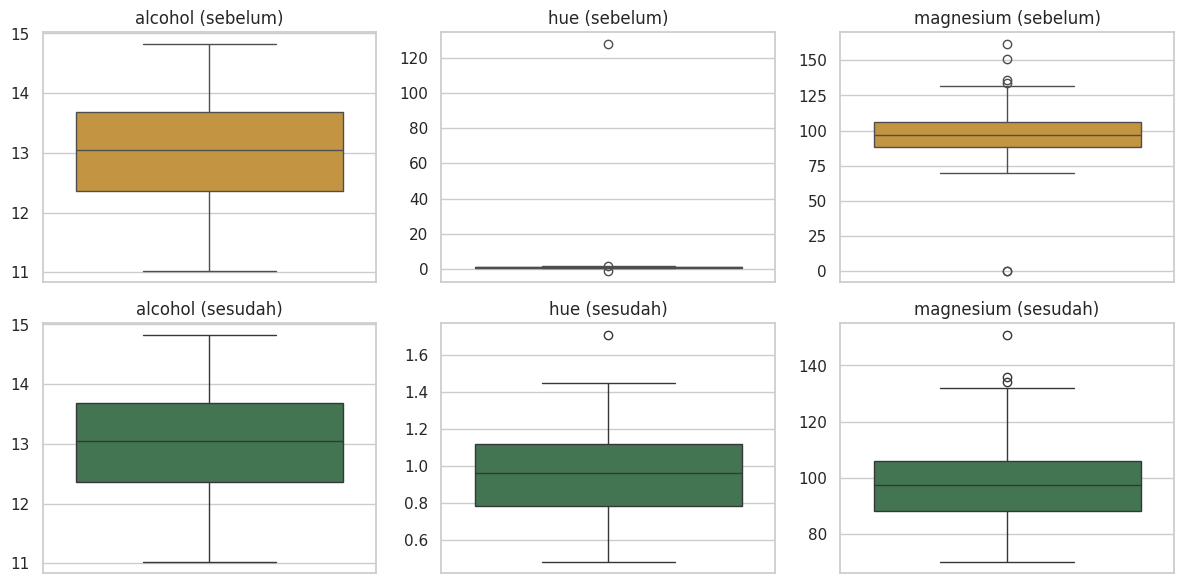

In [ ]:
# Langkah 7: tangani nilai TIDAK MASUK AKAL (bukan outlier biasa, tetapi kesalahan input)
# Aturan: (a) nilai <= 0 tidak mungkin pada ukuran kimia ini,
#         (b) nilai di luar "pagar ekstrem" Q1 - 3*IQR dan Q3 + 3*IQR dianggap salah skala.
# Outlier ringan (1,5*IQR) TIDAK dibuang karena bisa jadi variasi alami antar kultivar.
Q1, Q3 = df[fitur].quantile(0.25), df[fitur].quantile(0.75)
IQR = Q3 - Q1
bawah, atas = Q1 - 3 * IQR, Q3 + 3 * IQR

tak_valid = (df[fitur] <= 0) | (df[fitur] < bawah) | (df[fitur] > atas)
daftar = [(idx, k, df.loc[idx, k]) for k in fitur for idx in df.index[tak_valid[k]]]

print("Jumlah sel tidak masuk akal :", len(daftar))
for idx, k, v in daftar:
    alasan = "<= 0" if v <= 0 else "terlalu ekstrem"
    print(f"  {idx}  {k:30} nilai = {v:>9.2f}  ({alasan}; rentang wajar {max(bawah[k], 0):.2f} s.d. {atas[k]:.2f})")

# Visualisasi sebelum dan sesudah pada 3 contoh fitur
contoh = ["alcohol", "hue", "magnesium"]
sesudah = df[fitur].mask(tak_valid)
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for j, k in enumerate(contoh):
    sns.boxplot(y=df[k], ax=ax[0, j], color="#d99a2b"); ax[0, j].set_title(f"{k} (sebelum)")
    sns.boxplot(y=sesudah[k], ax=ax[1, j], color="#3b7d4f"); ax[1, j].set_title(f"{k} (sesudah)")
    ax[0, j].set_ylabel(""); ax[1, j].set_ylabel("")
plt.tight_layout()
plt.show()

df[fitur] = sesudah   # sel tidak valid diubah menjadi NaN, akan diisi pada tahap imputasi

Sembilan sel ditandai. Nilai seperti *hue* = 128, *color intensity* = 73, dan angka negatif jelas merupakan kesalahan input. Perhatikan bahwa **outlier ringan tidak dibuang**, karena nilai yang agak ekstrem dapat berupa variasi alami antar kultivar; hanya nilai yang jauh di luar pagar ekstrem (3 x IQR, aturan *far out* dari Tukey) yang dianggap salah. Boxplot sesudah penanganan menjadi jauh lebih proporsional.

### 3.10 Langkah 8: Missing Value Akhir

In [ ]:
# Langkah 8: ringkasan missing value final dan pembuangan baris yang terlalu kosong
n_kosong = df[fitur].isnull().sum(axis=1)
print("Sebaran jumlah fitur kosong per baris:")
print(n_kosong.value_counts().sort_index().to_string())

batas = len(fitur) // 2     # lebih dari 50% fitur kosong -> baris dibuang
buang = n_kosong[n_kosong > batas].index
print()
print(f"Baris dengan lebih dari {batas} fitur kosong : {len(buang)}")
df = df.drop(index=buang)

print()
print("Missing value per fitur (siap diimputasi):")
print((df[fitur].isnull().mean() * 100).round(2).astype(str).add(" %").to_string())
print()
print("Ukuran data bersih (belum diimputasi):", df.shape)

Sebaran jumlah fitur kosong per baris:
0    98
1    57
2    16
3     3

Baris dengan lebih dari 6 fitur kosong : 0

Missing value per fitur (siap diimputasi):
alcohol                 2.87 %
malic_acid              5.75 %
ash                      4.6 %
alcalinity_of_ash       5.17 %
magnesium                4.6 %
total_phenols           6.32 %
flavanoids              3.45 %
nonflavanoid_phenols    2.87 %
proanthocyanins         5.17 %
color_intensity         5.75 %
hue                     5.17 %
od280_od315              2.3 %
proline                  2.3 %

Ukuran data bersih (belum diimputasi): (174, 14)


Tidak ada baris yang terlalu kosong (maksimal 3 dari 13 fitur kosong), sehingga seluruh 174 baris dipertahankan dan sisa missing value (sekitar 2% sampai 6% per fitur) akan diisi dengan imputasi.

### 3.11 Langkah 9: Encoding Label

In [ ]:
# Langkah 9: encoding label (teks -> angka 0, 1, 2)
peta = {"Kultivar 1": 0, "Kultivar 2": 1, "Kultivar 3": 2}
df["target"] = df["kultivar"].map(peta).astype(int)
print(df[["kultivar", "target"]].drop_duplicates().sort_values("target").to_string(index=False))
print()
print("Distribusi kelas:")
print(df["kultivar"].value_counts().sort_index().to_string())

  kultivar  target
Kultivar 1       0
Kultivar 2       1
Kultivar 3       2

Distribusi kelas:
kultivar
Kultivar 1    59
Kultivar 2    68
Kultivar 3    47


### 3.12 Langkah 10: Pembagian Data Latih dan Data Uji

In [ ]:
# Langkah 10: pembagian data latih : data uji = 80 : 20 (stratified)
# Pembagian dilakukan SEBELUM imputasi dan scaling agar statistik dari data uji tidak "bocor" ke proses latih.
X = df[fitur]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Data latih :", X_train.shape, "| Data uji :", X_test.shape)
print("Jumlah per kelas (latih):", y_train.value_counts().sort_index().tolist())
print("Jumlah per kelas (uji)  :", y_test.value_counts().sort_index().tolist())

Data latih : (139, 13) | Data uji : (35, 13)
Jumlah per kelas (latih): [47, 54, 38]
Jumlah per kelas (uji)  : [12, 14, 9]


### 3.13 Langkah 11: Imputasi Missing Value

In [ ]:
# Langkah 11: imputasi missing value dengan KNN Imputer (k = 5)
# Sel kosong diisi dari rata-rata 5 sampel yang paling mirip (jarak dihitung pada data yang sudah distandarisasi).
# Seluruh parameter dipelajari HANYA dari data latih, lalu dipakai juga untuk data uji.
sc_imp = StandardScaler().fit(X_train)
knn = KNNImputer(n_neighbors=5).fit(sc_imp.transform(X_train))

def imputasi_knn(X_):
    hasil = knn.transform(sc_imp.transform(X_))
    return pd.DataFrame(sc_imp.inverse_transform(hasil), columns=fitur, index=X_.index)

X_train_imp = imputasi_knn(X_train)
X_test_imp  = imputasi_knn(X_test)

print("Missing value sebelum imputasi : latih =", int(X_train.isnull().sum().sum()), "| uji =", int(X_test.isnull().sum().sum()))
print("Missing value sesudah imputasi : latih =", int(X_train_imp.isnull().sum().sum()), "| uji =", int(X_test_imp.isnull().sum().sum()))

# Contoh satu baris: nilai sebelum dan sesudah imputasi
contoh = X_train.index[X_train.isnull().any(axis=1)][0]
kolom_kosong = X_train.columns[X_train.loc[contoh].isnull()].tolist()
print()
print(f"Contoh baris {contoh}: kolom kosong = {kolom_kosong}")
print("Nilai hasil imputasi:", X_train_imp.loc[contoh, kolom_kosong].round(2).to_dict())

Missing value sebelum imputasi : latih = 78 | uji = 20
Missing value sesudah imputasi : latih = 0 | uji = 0

Contoh baris S043: kolom kosong = ['alcalinity_of_ash', 'proanthocyanins']
Nilai hasil imputasi: {'alcalinity_of_ash': 17.94, 'proanthocyanins': 2.07}


Imputasi KNN dipilih karena memanfaatkan kemiripan antar sampel, sehingga nilai pengisi lebih masuk akal daripada satu angka tengah yang sama untuk semua baris. Pada Bagian 6, pilihan ini diuji terhadap median.

### 3.14 Langkah 12: Normalisasi

          rentang sebelum (min-max)  mean sesudah  std sesudah
proline            278.00 - 1510.00          -0.0          1.0
magnesium            70.00 - 151.00           0.0          1.0
alcohol               11.03 - 14.83           0.0          1.0
hue                     0.48 - 1.71           0.0          1.0


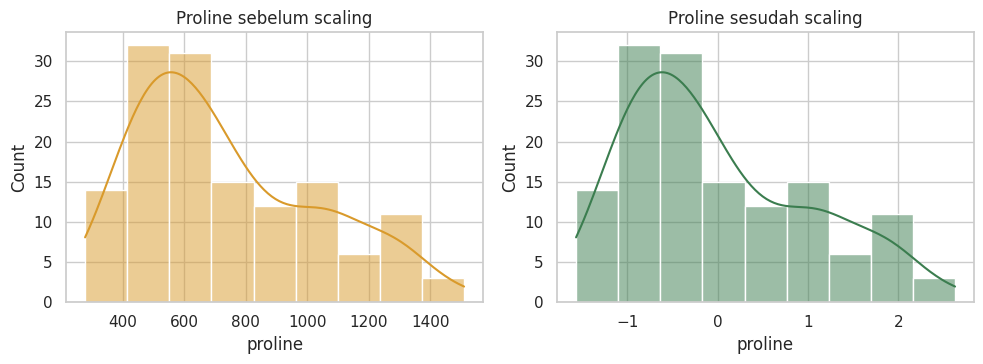

In [ ]:
# Langkah 12: normalisasi dengan StandardScaler (rata-rata 0, simpangan baku 1)
scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=fitur, index=X_train.index)
X_test_sc  = pd.DataFrame(scaler.transform(X_test_imp),      columns=fitur, index=X_test.index)

banding = pd.DataFrame({
    "rentang sebelum (min-max)": [f"{X_train_imp[c].min():.2f} - {X_train_imp[c].max():.2f}" for c in ["proline", "magnesium", "alcohol", "hue"]],
    "mean sesudah": X_train_sc[["proline", "magnesium", "alcohol", "hue"]].mean().round(3).values,
    "std sesudah":  X_train_sc[["proline", "magnesium", "alcohol", "hue"]].std(ddof=0).round(3).values,
}, index=["proline", "magnesium", "alcohol", "hue"])
print(banding.to_string())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
sns.histplot(X_train_imp["proline"], kde=True, color="#d99a2b", ax=ax[0]); ax[0].set_title("Proline sebelum scaling")
sns.histplot(X_train_sc["proline"],  kde=True, color="#3b7d4f", ax=ax[1]); ax[1].set_title("Proline sesudah scaling")
plt.tight_layout()
plt.show()

Setelah normalisasi, semua fitur memiliki rata-rata 0 dan simpangan baku 1 (dihitung dari data latih), sehingga fitur berskala besar seperti *proline* tidak mendominasi perhitungan jarak pada algoritma seperti KNN dan SVM. Bentuk sebaran datanya tidak berubah, hanya skalanya.

### 3.15 Langkah 13: Menyimpan Hasil

In [ ]:
# Langkah 13: simpan hasil preprocessing
bersih = pd.concat([X_train_imp.assign(split="train"), X_test_imp.assign(split="test")])
bersih["kultivar"] = df.loc[bersih.index, "kultivar"]
bersih["target"] = df.loc[bersih.index, "target"]
bersih.sort_index().to_csv("data_anggur_bersih.csv")

siap = pd.concat([X_train_sc.assign(split="train"), X_test_sc.assign(split="test")])
siap["target"] = df.loc[siap.index, "target"]
siap.sort_index().to_csv("data_anggur_siap_model.csv")

print("Tersimpan: data_anggur_bersih.csv      ->", bersih.shape, "(sudah bersih & diimputasi, belum diskalakan)")
print("Tersimpan: data_anggur_siap_model.csv  ->", siap.shape, "(sudah diskalakan, siap untuk modeling)")
print()
print("Cuplikan data_anggur_bersih.csv:")
print(bersih.sort_index().head(5).round(2).to_string())

Tersimpan: data_anggur_bersih.csv      -> (174, 16) (sudah bersih & diimputasi, belum diskalakan)
Tersimpan: data_anggur_siap_model.csv  -> (174, 15) (sudah diskalakan, siap untuk modeling)

Cuplikan data_anggur_bersih.csv:
           alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  od280_od315  proline  split    kultivar  target
id_sampel                                                                                                                                                                                                   
S001         14.23        1.71  2.43               15.6      127.0           2.80        3.06                  0.28             2.29             5.64  1.04         3.92   1065.0  train  Kultivar 1       0
S002         13.20        1.78  2.14               11.2      100.0           2.65        2.76                  0.26             1.28             4.38  1.05      

---
## 4. Validasi Hasil Preprocessing

Karena data asli UCI diketahui, hasil pembersihan dapat dibandingkan dengan "kunci jawabannya".

### 4.1 Ketepatan Pembersihan dan Imputasi

In [ ]:
# VALIDASI 1: seberapa tepat hasil pembersihan? (hanya bisa dilakukan karena kita punya data asli UCI sebagai kunci)
asli = load_wine(as_frame=True).frame
asli.index = [f"S{i + 1:03d}" for i in range(len(asli))]
asli_fitur = asli[load_wine().feature_names]
asli_fitur.columns = fitur

bersih_cek = pd.read_csv("data_anggur_bersih.csv", index_col=0)
idx = bersih_cek.index
sebelum_imp = df.loc[idx, fitur]                 # nilai setelah dibersihkan, sebelum imputasi
kosong_mask = sebelum_imp.isnull()
isi_mask = ~kosong_mask
std = asli_fitur.std()

# a) Sel yang TIDAK kosong: apakah sama persis dengan data asli? (menguji perbaikan koma, satuan, dll.)
sama = np.isclose(sebelum_imp.to_numpy(float), asli_fitur.loc[idx].to_numpy(float), equal_nan=True) & isi_mask.to_numpy()
print(f"a) Sel terisi yang cocok dengan data asli : {int(sama.sum())} dari {int(isi_mask.to_numpy().sum())}")

# b) Aturan "nilai tidak masuk akal": berapa yang memang salah input?
benar_salah = [(i, k, v) for i, k, v in daftar if not np.isclose(v, asli_fitur.loc[i, k])]
sah = [(i, k, v) for i, k, v in daftar if np.isclose(v, asli_fitur.loc[i, k])]
print(f"b) Sel yang ditandai tidak valid          : {len(daftar)}")
print(f"   - benar-benar salah input              : {len(benar_salah)}")
print(f"   - sebenarnya nilai asli yang sah       : {len(sah)}", [f"{i}/{k}={v:g}" for i, k, v in sah])

# c) Imputasi: seberapa dekat dengan nilai aslinya? (error dalam satuan simpangan baku; makin kecil makin baik)
err_knn = ((bersih_cek[fitur] - asli_fitur.loc[idx]).abs() / std).where(kosong_mask)
med = SimpleImputer(strategy="median").fit(X_train)
med_hasil = pd.DataFrame(med.transform(sebelum_imp), columns=fitur, index=idx)
err_med = ((med_hasil - asli_fitur.loc[idx]).abs() / std).where(kosong_mask)
print(f"c) Jumlah sel yang diimputasi              : {int(kosong_mask.to_numpy().sum())}")
print(f"   Rata-rata error imputasi KNN (dipakai)  : {np.nanmean(err_knn.to_numpy()):.3f} simpangan baku")
print(f"   Rata-rata error imputasi median (pembanding): {np.nanmean(err_med.to_numpy()):.3f} simpangan baku")

a) Sel terisi yang cocok dengan data asli : 2164 dari 2164
b) Sel yang ditandai tidak valid          : 9
   - benar-benar salah input              : 8
   - sebenarnya nilai asli yang sah       : 1 ['S096/magnesium=162']
c) Jumlah sel yang diimputasi              : 98
   Rata-rata error imputasi KNN (dipakai)  : 0.593 simpangan baku
   Rata-rata error imputasi median (pembanding): 0.831 simpangan baku


Interpretasi:
- **Seluruh 2.164 sel yang terisi cocok 100%** dengan data asli, artinya perbaikan koma, satuan, dan konversi tipe tidak merusak satu nilai pun.
- Dari 9 sel yang ditandai tidak masuk akal, **8 memang salah input**, tetapi **1 sebenarnya nilai asli yang sah** (magnesium sampel S096 = 162, nilai tertinggi yang memang ada di data UCI). Ini kelemahan aturan otomatis: ia tidak memahami konteks, sehingga satu nilai valid ikut dianggap salah dan diganti hasil imputasi.
- Pada 98 sel yang diimputasi, **KNN lebih dekat ke nilai asli** (error rata-rata 0,59 simpangan baku) dibandingkan median (0,83), sehingga KNN adalah pilihan yang tepat.

### 4.2 Pengaruh terhadap Kinerja Model

                                    Jumlah baris  Akurasi CV     Std
Data asli UCI (acuan)                        178      0.9833  0.0222
Cara naif (hapus baris bermasalah)            61      0.9333  0.0624
Hasil preprocessing kita                     174      0.9771  0.0214


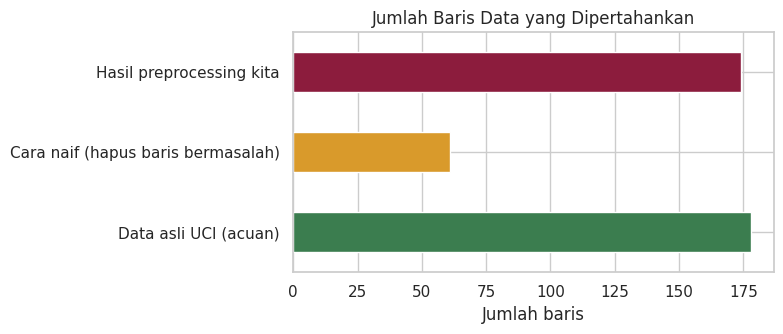

In [ ]:
# VALIDASI 2: apakah preprocessing benar-benar membantu model? (SVM RBF, 5-fold cross validation)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_acc(X_, y_, imputasi=False):
    langkah = [("sc", StandardScaler())] + ([("imp", KNNImputer(n_neighbors=5))] if imputasi else []) + [("svm", SVC(random_state=RANDOM_STATE))]
    s = cross_val_score(Pipeline(langkah), X_, y_, cv=skf, scoring="accuracy")
    return s.mean(), s.std()

# (A) Data asli UCI sebagai acuan
a_mean, a_std = cv_acc(asli_fitur, asli["target"])

# (B) Cara naif: paksa jadi angka lalu buang semua baris yang bermasalah (tanpa perbaikan apa pun)
naif = raw.copy()
naif.columns = [rapikan(c) for c in naif.columns]
for c in fitur:
    naif[c] = pd.to_numeric(naif[c], errors="coerce")
naif["target"] = naif["kultivar"].map({"Kultivar 1": 0, "Kultivar 2": 1, "Kultivar 3": 2})
naif = naif.dropna(subset=fitur + ["target"])
b_mean, b_std = cv_acc(naif[fitur], naif["target"].astype(int))

# (C) Hasil preprocessing kita (imputasi dilakukan DI DALAM pipeline agar tidak bocor antar fold)
c_mean, c_std = cv_acc(df[fitur], df["target"], imputasi=True)

hasil = pd.DataFrame({
    "Jumlah baris": [len(asli_fitur), len(naif), len(df)],
    "Akurasi CV": [a_mean, b_mean, c_mean],
    "Std": [a_std, b_std, c_std],
}, index=["Data asli UCI (acuan)", "Cara naif (hapus baris bermasalah)", "Hasil preprocessing kita"]).round(4)
print(hasil.to_string())

plt.figure(figsize=(8, 3.5))
hasil["Jumlah baris"].plot(kind="barh", color=["#3b7d4f", "#d99a2b", "#8c1c3d"])
plt.title("Jumlah Baris Data yang Dipertahankan")
plt.xlabel("Jumlah baris")
plt.tight_layout()
plt.show()

Interpretasi:
- **Cara naif** (membuang semua baris yang bermasalah tanpa perbaikan) hanya menyisakan **61 dari 187 baris** dan akurasinya turun serta kurang stabil (simpangan baku 6,24%).
- **Hasil preprocessing** mempertahankan **174 baris** dan akurasi cross validation (97,71%) sangat dekat dengan data asli yang bersih (98,33%).
- Selisih kecil antara 97,71% dan 98,33% masih dalam kisaran simpangan baku, sehingga tidak perlu dibaca sebagai kerugian yang pasti. Dataset ini juga kecil dan hanya diuji dengan satu skema cross validation.

---
## 5. Ringkasan Hasil

| Tahap | Sebelum | Sesudah |
|---|---|---|
| Jumlah baris | 187 (termasuk 9 duplikat, 4 tanpa label) | **174** baris bersih |
| Jumlah kolom | 16 | 13 fitur + label + target |
| Variasi penulisan label | 18 (+3 token kosong) | 3 kelas |
| Tipe kolom fitur | teks (object) | `float64` |
| Missing value pada fitur | 94 sel (3,87%) + token tidak seragam | 0 (setelah imputasi KNN) |
| Nilai tidak masuk akal | 10 sel (8 tersisa setelah baris dibersihkan) | ditangani, 1 salah tandai |
| Baris duplikat | 9 | 0 |
| Skala fitur | proline sampai ribuan, hue sekitar 1 | rata-rata 0, simpangan baku 1 |
| Akurasi SVM (5-fold CV) | 93,33% pada cara naif (61 baris) | **97,71%** (174 baris) |

**File keluaran:**
- `data_anggur_bersih.csv`: data bersih dan sudah diimputasi, belum diskalakan, dengan kolom `split` (train/test).
- `data_anggur_siap_model.csv`: fitur sudah diskalakan, siap dipakai untuk tahap klasifikasi.

## 6. Kesimpulan dan Keterbatasan

**Kesimpulan:** Preprocessing yang sistematis (audit, perbaikan format, penyeragaman label, penghapusan duplikat, penandaan nilai tidak wajar, imputasi, dan normalisasi) berhasil memulihkan data mentah yang kotor menjadi data yang hampir sama baiknya dengan data asli, sambil mempertahankan 174 dari 178 sampel asli. Memisahkan data latih dan uji **sebelum** imputasi dan scaling menjaga evaluasi tetap jujur.

**Keterbatasan:**
- Data kotor bersifat **simulasi**; masalah pada data nyata biasanya lebih beragam dan sulit ditebak.
- Empat sampel hilang karena labelnya kosong dan tidak dapat dipulihkan.
- Pagar ekstrem 3 x IQR adalah aturan heuristik dan terbukti salah menandai 1 nilai yang sah.
- Hasil imputasi tetap merupakan perkiraan, bukan nilai sebenarnya.
- Data hanya 174 baris sehingga estimasi akurasi memiliki ketidakpastian yang cukup besar.

**Saran pengembangan:** konfirmasi nilai yang ditandai kepada sumber data bila memungkinkan, coba beberapa nilai k pada KNN, dan gunakan repeated cross validation.

## Referensi

1. Aeberhard, S., & Forina, M. (1991). *Wine* [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/109/wine
2. Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.
3. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.
4. Dokumentasi scikit-learn (SimpleImputer, KNNImputer, StandardScaler): https://scikit-learn.org/stable/